[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_calm/BA_L2_calm.ipynb)

# BA_L2_calm: Calm Follows Calm

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Mean absolute daily return by quintile of the previous day's absolute return, Bitcoin and the S&P 500, 2018 to 18 September 2026: a direct view of volatility clustering.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

`close_cal(sym, start)` keeps each asset on its own calendar: crypto trades every day; for the S&P 500 and gold only
Monday–Friday closes are kept and repeated closes (holidays filled with the last price) are removed.
`log_returns(sym)` gives the daily log returns in percent, $r_t = 100(\ln P_t - \ln P_{t-1})$, of 2018–2026.

The days are sorted into five groups of equal size (quintiles) by yesterday's absolute return $|r_{t-1}|$; each bar is
the mean of today's absolute return $|r_t|$ in that group.

**How to read the chart.** If the size of yesterday's move carried no information, the five bars would all be at the
dashed line (the mean over all days). Rising bars mean that turbulent days follow turbulent days.

In [5]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]

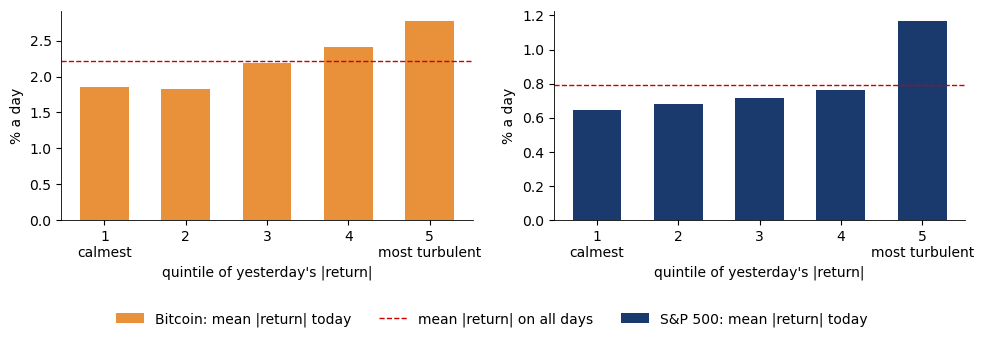

Bitcoin: mean |r_t| by quintile of |r_(t-1)|: 1.86, 1.83, 2.19, 2.40, 2.77 (all days 2.21); most turbulent / calmest = 1.49
S&P 500: mean |r_t| by quintile of |r_(t-1)|: 0.65, 0.68, 0.72, 0.76, 1.17 (all days 0.79); most turbulent / calmest = 1.80


In [6]:
# calm follows calm: mean |r_t| by quintile of |r_(t-1)|, 2018-2026
calm = {}
for nm, sym in [('Bitcoin', 'BTC-USD.CC'), ('S&P 500', 'GSPC.INDX')]:
    a_ = log_returns(sym).abs()
    q_ = pd.qcut(a_.shift(1), 5, labels=False)
    calm[nm] = (a_.groupby(q_).mean(), a_.mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a_, (nm, col) in zip(ax, [('Bitcoin', BTC), ('S&P 500', BLUE)]):
    g_, m_ = calm[nm]
    a_.bar(np.arange(1, 6), g_.values, color=col, width=0.6, label=f'{nm}: mean |return| today')
    a_.axhline(m_, color=RED, ls='--', lw=1, label=('mean |return| on all days' if nm == 'S&P 500' else None))
    a_.set_xticks(range(1, 6)); a_.set_xticklabels(['1\ncalmest', '2', '3', '4', '5\nmost turbulent'])
    a_.set_xlabel('quintile of yesterday\'s |return|'); a_.set_ylabel('% a day')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_calm')
for nm, (g_, m_) in calm.items():
    print(f'{nm}: mean |r_t| by quintile of |r_(t-1)|:', ', '.join(f'{v:.2f}' for v in g_.values),
          f'(all days {m_:.2f}); most turbulent / calmest = {g_.iloc[-1] / g_.iloc[0]:.2f}')